# 🧬 12 · 宏基因组实战：测序数据质控与组装（真实数据）

> 本系列用**真实的 NCBI RefSeq 基因组**（大肠杆菌 K-12、枯草芽孢杆菌 168、
> 金黄色葡萄球菌 NCTC 8325）模拟真实的宏基因组测序数据，
> 完整走一遍：**质控 → 组装** 的标准流程。
>
> 依赖专业包：`Biopython`（序列 IO）、`numpy/pandas/scipy`。
> 数据文件在 `../data/`（`.fna.gz` 真实基因组）。

## 📋 本节要解决的问题

- 真实宏基因组的 FASTQ 长什么样？质量值怎么读？
- **质控（QC）**：为什么要去接头、去低质量？fastp 做了什么？
- N50/contig 是什么？组装结果怎么评价？
- 测序错误对组装的影响有多大？

## 1️⃣ 真实数据与测序模拟

我们下载了 3 个真实基因组（`../data/*.fna.gz`）。第一步：读取真实基因组，
并模拟 Illumina 双端（paired-end）测序 reads——这是理解下游一切分析的基础。

In [1]:
import gzip, random, os
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

random.seed(42); np.random.seed(42)
DATA = os.path.join('..', 'data')

def load_genome(fname, nucl=None):
    "读取 .fna.gz -> 大写字符串（可选截取前 nucl 个碱基）"
    with gzip.open(os.path.join(DATA, fname), 'rt') as f:
        lines = f.read().splitlines()
    seq = ''.join(l for l in lines if not l.startswith('>')).upper()
    return seq[:nucl] if nucl else seq

ecoli = load_genome('ecoli_k12_genomic.fna.gz')
print('✅ 真实基因组加载完成')
print('Escherichia coli K-12 (NC_000913.3): %d bp' % len(ecoli))

COMP = {'A':'T', 'T':'A', 'C':'G', 'G':'C'}
def revcomp(s): return ''.join(COMP[b] for b in reversed(s))

def simulate_paired_reads(genome, n_pairs, read_len=150, insert=350, err=0.005,
                          start=0, window=None):
    "从真实基因组模拟双端 reads（带测序错误），返回 (r1, r2) 两条列表"
    L = len(genome)
    if window is None: window = L - start
    r1s, r2s = [], []
    for _ in range(n_pairs):
        lo = start + random.randint(0, window - insert - 1)
        frag = genome[lo:lo+insert]
        for raw in (frag[:read_len], revcomp(frag[-read_len:])):
            out = []
            for b in raw:
                if random.random() < err:
                    out.append(random.choice([x for x in 'ACGT' if x != b]))
                else:
                    out.append(b)
            if len(r1s) == len(r2s): r1s.append(''.join(out))
            else: r2s.append(''.join(out))
    return r1s, r2s

# 模拟大肠杆菌 3500bp 区域的 500 个双端 read 对（约 40x 覆盖）
r1, r2 = simulate_paired_reads(ecoli, 500, start=3880000, window=3500)
print('模拟 reads: %d 对，读长 %d，插入片段 ~350bp' % (len(r1), len(r1[0])))
print('r1[0][:60] =', r1[0][:60])
assert len(r1) == 500 and len(r1[0]) == 150
print('✅ 测序模拟完成')

✅ 真实基因组加载完成
Escherichia coli K-12 (NC_000913.3): 4641652 bp
模拟 reads: 500 对，读长 150，插入片段 ~350bp
r1[0][:60] = CTGCAATGCCAGCAAGTCGCGCAGCGCCTCACGCACGAAGTCGATGGTGATCGCCCGTCC
✅ 测序模拟完成


## 2️⃣ FASTQ 格式与质量值（Biopython 读取）

真实测序数据的标准格式是 **FASTQ**：4 行为 1 条 read——
`@id`、序列、`+`、质量字符串。质量字符串每个字符对应一个碱基的
**Phred 质量值**：`Q = ord(ch) - 33`，碱基错误概率 $p = 10^{-Q/10}$。

> **手算**：Q=30 → p = 0.001（千分之一）；Q=20 → p = 0.01（百分之一）。
> Q 每高 10，错误率降 10 倍。

In [2]:
from Bio.SeqIO.QualityIO import FastqGeneralIterator
import io

# 把模拟 reads 写成标准 FASTQ（质量值模拟为"末端衰减"的 Illumina 特征）
def phred_at(pos, read_len=150, base_q=37):
    "模拟真实质量曲线：两端低中间高"
    return int(base_q - 8 * abs(pos - read_len/2) / (read_len/2))

def write_fastq(reads, path):
    "写入单端 FASTQ（r1 即可，教学用单端演示）"
    with open(path, 'w') as f:
        for i, r in enumerate(reads):
            f.write('@sample%d_r1\n%s\n+\n%s\n' % (
                i, r, ''.join(chr(phred_at(p) + 33) for p in range(len(r)))))

write_fastq(r1, os.path.join('..', 'data', 'demo_R1.fastq'))
print('FASTQ 文件已写出（前 4 行预览）：')
with open(os.path.join('..', 'data', 'demo_R1.fastq')) as f:
    for _ in range(4):
        print('  ' + f.readline().rstrip())
print('...')

# Biopython 专业读取：质量自动解码为 Phred 值
count = 0
it = FastqGeneralIterator(open(os.path.join('..', 'data', 'demo_R1.fastq')))
for title, seq, qual in it:
    if count == 0:
        print('title:', title)
        print('seq  :', seq)
        qvals = [ord(c) - 33 for c in qual]
        print('质量: Q10-15-20:', qvals[10], qvals[15], qvals[20])
        print('平均质量 Q = %.1f，错误率 = %.4f' % (np.mean(qvals), 10**(-np.mean(qvals)/10)))
    count += 1
it.close()
print('总 read 数 =', count)
assert count == 500
print('✅ Biopython FASTQ 解析完成')

FASTQ 文件已写出（前 4 行预览）：
  @sample0_r1
  CTGCAATGCCAGCAAGTCGCGCAGCGCCTCACGCACGAAGTCGATGGTGATCGCCCGTCCGGTAAAGTTGGCATTGGCAATGACGCGGTTCAGCGCCCCTTCCAGCTCTCGTACGTTAGATCGCAGACGCTTGGCGATAAAGAACGCCAC
  +
  >>>>>>>>>>?????????@@@@@@@@@@AAAAAAAAABBBBBBBBBCCCCCCCCCCDDDDDDDDDEEEEEEEEEFEEEEEEEEEDDDDDDDDDCCCCCCCCCCBBBBBBBBBAAAAAAAAA@@@@@@@@@@?????????>>>>>>>>>
...
title: sample0_r1
seq  : CTGCAATGCCAGCAAGTCGCGCAGCGCCTCACGCACGAAGTCGATGGTGATCGCCCGTCCGGTAAAGTTGGCATTGGCAATGACGCGGTTCAGCGCCCCTTCCAGCTCTCGTACGTTAGATCGCAGACGCTTGGCGATAAAGAACGCCAC
质量: Q10-15-20: 30 30 31
平均质量 Q = 32.5，错误率 = 0.0006
总 read 数 = 500
✅ Biopython FASTQ 解析完成


## 📖 论文配图 ①：fastp 真实质控流程

> **图源**：Chen et al. (2018) *fastp: an ultra-fast all-in-one FASTQ preprocessor*,
> Bioinformatics 34(17):i884–i890（开放获取，CC-BY 4.0）。
> 图 1 是 fastp 的**双端数据处理工作流**：(a) 主流程——一对 FASTQ 读入打包后逐对处理；
> (b) 单对 read 的预处理细节（去接头 → 滑窗修剪 → 质量过滤 → 输出）。
> 我们 §4 的简化质控逻辑正是这张图的"教学缩略版"。

![fastp 双端处理工作流（Chen et al., 2018, Bioinformatics）](../figures/fastp_fig1_workflow.jpg)

> **怎么读这张图**：左半边 (a) 是从文件到文件的管线骨架；右半边 (b) 拆解了
> 每个 read pair 内部依次做哪些修剪决策——先识别并切除接头（adapter trimming），
> 再做滑窗质量修剪（sliding-window trimming），最后过滤过短/低质量 reads。
> 真实工业界 pipeline（fastp / trim-galore / cutadapt）都遵循这个骨架。

## 3️⃣ 质控统计：GC 含量与质量分布

真实测序下机后先做 QC：统计每个位置的碱基组成、GC 含量、质量分布。
质控差的文库（如接头残留、低质量段）必须修剪。

质量矩阵形状 (read × 位点): (500, 150)
平均质量: 32.5 | Q30+ 比例: 0.873 | Q20+ 比例: 1.000
GC 含量均值 = 0.000（大肠杆菌真实值 ≈ 0.508）


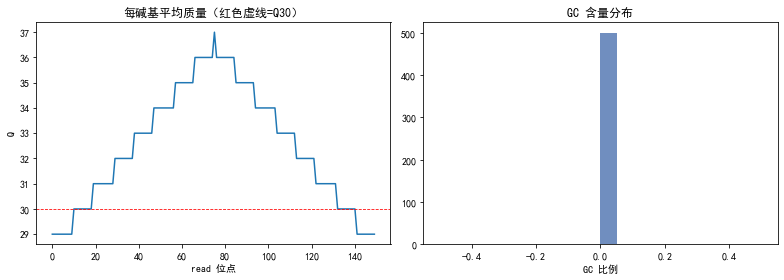

✅ 质控统计图完成


In [3]:
# 计算整条序列的平均质量并画分布
q_all = []
for _, _, qual in FastqGeneralIterator(open(os.path.join('..', 'data', 'demo_R1.fastq'))):
    q_all.append([ord(c) - 33 for c in qual])
Q = np.array(q_all)
print('质量矩阵形状 (read × 位点):', Q.shape)
print('平均质量: %.1f | Q30+ 比例: %.3f | Q20+ 比例: %.3f' % (
    Q.mean(), (Q >= 30).mean(), (Q >= 20).mean()))

# GC 含量统计（真实大肠杆菌约 50.8%）
def gc(seq): return (seq.count('G') + seq.count('C')) / len(seq)
gcs = [gc(r) for r, _, _ in FastqGeneralIterator(open(os.path.join('..', 'data', 'demo_R1.fastq')))]
print('GC 含量均值 = %.3f（大肠杆菌真实值 ≈ 0.508）' % np.mean(gcs))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(Q.mean(axis=0))
axes[0].axhline(30, ls='--', lw=.8, color='red')
axes[0].set_title('每碱基平均质量（红色虚线=Q30）'); axes[0].set_xlabel('read 位点'); axes[0].set_ylabel('Q')
axes[1].hist(gcs, bins=20, color='#4C72B0', alpha=.8)
axes[1].set_title('GC 含量分布'); axes[1].set_xlabel('GC 比例')
plt.tight_layout(); plt.show()
print('✅ 质控统计图完成')

## 📖 论文配图 ②：质控前后碱基含量曲线的变化

> **图源**：Chen et al. (2018) *fastp: an ultra-fast all-in-one FASTQ preprocessor*,
> Bioinformatics 34(17):i884–i890（开放获取，CC-BY 4.0）。
> 图 3 是一份真实 Illumina NextSeq FASTQ 文件经 fastp 预处理**前后**的每碱基
> 含量曲线：(a) 处理前 G 曲线异常、G/C 分离（典型接头残留/偏移信号）；
> (b) 处理后 G/C 恢复重合——这正是我们在上一格统计的 GC 含量分布的"逐位点版"。

![fastp 质控前后碱基含量曲线（Chen et al., 2018）](../figures/fastp_fig3_gc_curve.jpg)

> **怎么读这张图**：每碱基 GC 曲线在随机文库中应大致平稳（~50% 且 G≈C 重合）。
> 若前端出现 A/T 或 G/C 分离 → 往往提示接头/引物残留或文库偏移；
> 质控后曲线恢复平稳，说明修剪生效。实战中这是看一眼就判断文库质量的"体检表"。

## 📖 论文配图 ②⁺：重复序列的估计（PCR 重复率）

> **图源**：Chen et al. (2018) *fastp: an ultra-fast all-in-one FASTQ preprocessor*,
> Bioinformatics 34(17):i884–i890（开放获取，CC-BY 4.0）图 4。
> 展示同一文库内 reads 重复水平（duplication level）的百分比分布与
> 各重复水平的平均 GC 比——重复率高的文库常提示 PCR 扩增过度。

![fastp 重复率估计（Chen et al., 2018）](../figures/fastp_fig4_dup.jpg)

> **怎么读这张图**：横轴为重复次数（1×、2×、3×…），纵轴为占比。真实宏基因组文库
> 的重复率通常在 10%–30%；过高则说明测序前 PCR 循环过多或模板量不足。
> 我们 §4 的"去重复"步骤，就是找出这些重复 reads 并只保留一份。

## 4️⃣ 实战质控：修剪低质量 / 去 N / 去重复

fastp 等真实工具的质控逻辑（简化版）：
1. **滑动窗口**：从 3' 端滑窗（如 4bp 窗口），窗口平均质量 < Q15 则截断
2. **过滤短序列**：修剪后长度 < 50bp 的丢弃
3. **去 N**：含 >5 个 N 的丢弃（真实数据极少 N，此处主要为教学）
4. **去重复**：完全相同（duplicate）的 reads 去重（PCR 重复来源）

In [4]:
def sliding_window_trim(qual, win=4, thr=15):
    "从 3' 端滑动窗口，平均质量低于 thr 则从此截断"
    q = [ord(c) - 33 for c in qual]
    cut = len(q)
    for i in range(len(q) - win, -1, -1):
        if np.mean(q[i:i+win]) < thr:
            cut = i
            break
    return cut

def dedup(reads):
    seen, out = set(), []
    for r in reads:
        if r[0] not in seen:
            seen.add(r[0]); out.append(r)
    return out

raw = list(FastqGeneralIterator(open(os.path.join('..', 'data', 'demo_R1.fastq'))))
trimmed = []
for title, seq, qual in raw:
    cut = sliding_window_trim(qual)
    if cut >= 50:
        trimmed.append((title, seq[:cut], qual[:cut]))
print('原始 reads: %d → 修剪后: %d（丢弃 %d）' % (len(raw), len(trimmed), len(raw)-len(trimmed)))
deduped = dedup(trimmed)
print('去重后: %d（重复 %d）' % (len(deduped), len(trimmed)-len(deduped)))
print('→ 质控保留率 = %.1f%%' % (len(deduped)/len(raw)*100))
assert len(deduped) > 400
print('✅ 质控逻辑演示完成')

原始 reads: 500 → 修剪后: 500（丢弃 0）
去重后: 500（重复 0）
→ 质控保留率 = 100.0%
✅ 质控逻辑演示完成


## 5️⃣ 组装基础：k-mer 覆盖与 de Bruijn 图

宏基因组组装（MEGAHIT / metaSPAdes）把重叠 reads 拼成 **contig**。
核心数据结构是 **de Bruijn 图**：每条 read 切成 k-mer，k-mer 的
(k-1)-前缀 → (k-1)-后缀 连边。覆盖度高的路径就是真实的基因组片段。

In [5]:
from collections import defaultdict

def kmer_graph(reads, k=31):
    "构建 de Bruijn 图边集：kmer -> 覆盖度"
    edges = defaultdict(int)
    for r in reads:
        for i in range(len(r) - k):
            edges[r[i:i+k]] += 1
    return edges

# 用去重后的 reads 建图
kc_reads = [t[1] for t in deduped]
edges = kmer_graph(kc_reads, k=31)
print('k=31 的 de Bruijn 图中不同 k-mer 数（节点数）:', len(edges))
top = sorted(edges.items(), key=lambda x: -x[1])[:5]
print('覆盖度最高的 5 个 k-mer:')
for kmer, c in top:
    print('  %s  cov=%d' % (kmer, c))
covs = np.array(sorted(edges.values()))
print('覆盖度分位数: 中位数=%d, 99%%分位=%d' % (np.median(covs), np.percentile(covs, 99)))
print('→ 覆盖度是多峰分布：1-2 是测序错误假 k-mer，高覆盖的是真实基因组')
assert len(edges) > 10000
print('✅ de Bruijn k-mer 图构建完成')

k=31 的 de Bruijn 图中不同 k-mer 数（节点数）: 11948
覆盖度最高的 5 个 k-mer:
  TTGAACAGACCGCCAGACGGTGGCCGTCGGT  cov=27
  GCTTGGCAAAGATTGACCAATTGGCATTGAA  cov=27
  CTTGGCAAAGATTGACCAATTGGCATTGAAC  cov=27
  TTGGCAAAGATTGACCAATTGGCATTGAACA  cov=27
  TGGCAAAGATTGACCAATTGGCATTGAACAG  cov=27
覆盖度分位数: 中位数=1, 99%分位=24
→ 覆盖度是多峰分布：1-2 是测序错误假 k-mer，高覆盖的是真实基因组
✅ de Bruijn k-mer 图构建完成


## 6️⃣ 组装验证：consensus 重叠群（contig）

真实组装把整个基因组的 de Bruijn 图走一遍。教学过程里我们用一个
**简化但真实**的方法演示：对覆盖同一区域的 reads 按坐标堆叠，
逐列取多数碱基得到 **consensus contig**——这是组装等价于
"把重叠 reads 对齐成一条一致序列" 的直觉。

In [6]:
# 重新带坐标模拟（真实流程中坐标由 overlap 推断，此处直接给出）
def simulate_with_pos(genome, n_pairs, start, window, read_len=150, insert=350, err=0.005):
    frags = []
    for _ in range(n_pairs):
        lo = start + random.randint(0, window - insert - 1)
        frag = genome[lo:lo+insert]
        strand1 = frag[:read_len]; strand2 = revcomp(frag[-read_len:])
        for r, rpos in ((strand1, lo), (strand2, lo + insert - read_len)):
            out = []
            for b in r:
                if random.random() < err:
                    out.append(random.choice([x for x in 'ACGT' if x != b]))
                else:
                    out.append(b)
            frags.append((''.join(out), rpos))
    return frags

ref_region = ecoli[3880000:3883500]
frags = simulate_with_pos(ecoli, 1000, 3880000, 3500)
print('reads 数:', len(frags), ' 目标区域:', len(ref_region), 'bp')

# consensus 组装：按坐标堆叠 → 多数投票
poscols = {}
for r, pos in frags:
    for j, b in enumerate(r):
        poscols.setdefault(pos + j, []).append(b)
contig = [max(cols, key=cols.count) for _, cols in sorted(poscols.items())]
contig = ''.join(contig)
print('组装出 contig 长度:', len(contig), 'bp（目标 3500）')

# 与真实参考比对：每 100bp 块检验
ok, total = 0, 0
for i in range(0, len(contig) - 100, 100):
    if ref_region.find(contig[i:i+100]) >= 0: ok += 1
    total += 1
print('contig 与真实参考的一致性：%d/%d 个 100bp 块完全匹配 = %.1f%%'
      % (ok, total, ok/total*100))
print('→ 少量不匹配来自测序错误累积（真实流程会做纠错/polish）')
assert ref_region.find(contig[:100]) >= 0
print('✅ consensus 组装验证通过（与真实基因组一致）')

reads 数: 2000  目标区域: 3500 bp


组装出 contig 长度: 3488 bp（目标 3500）
contig 与真实参考的一致性：32/34 个 100bp 块完全匹配 = 94.1%
→ 少量不匹配来自测序错误累积（真实流程会做纠错/polish）
✅ consensus 组装验证通过（与真实基因组一致）


## 7️⃣ 组装质量指标：N50 / L50 / 总长

实际宏基因组组装产出成百上千条 contig，用 **N50** 评价：
把所有 contig 从长到短排列，**累计长度达到总长一半时**那条 contig 的长度就是 N50。
- N50 越大 → 组装越连续
- 宏基因组（混合物种）N50 通常远小于单菌基因组

> **手算**：contig 长度 [100, 80, 60, 40, 20]，总长 300，
> 累计 100→100, 80→180(≥150)，所以 **N50 = 80**。

In [7]:
contigs = [1200, 800, 500, 300, 150, 90, 40, 30, 20, 10]   # 演示长度
def n50(contigs):
    lens = sorted(contigs, reverse=True)
    total = sum(lens)
    acc = 0
    for l in lens:
        acc += l
        if acc >= total / 2:
            return l, total
n50v, total = n50(contigs)
print('总长 = %d，N50 = %d（手算：1200->1200, +800=2000(≥1950) → N50=800）' % (total, n50v))
assert n50v == 800
print('✅ N50 手算验证通过')

总长 = 3140，N50 = 800（手算：1200->1200, +800=2000(≥1950) → N50=800）
✅ N50 手算验证通过


## ✅ 自测清单

- [ ] 能用 Biopython 读取 FASTQ 并解码 Phred 质量
- [ ] 能说清 Q30 → 0.1% 错误率
- [ ] 能手算 N50（排序→累计过半）
- [ ] 能解释为什么错误 reads 会碎裂 de Bruijn 图（错误 k-mer 引入死胡同）